# ЛР №3 — довірчий розрахунок справедливості (п. 4.6) і вплив SMOTE на захищену ознаку (п. 4.3)


In [1]:
import sys, os, json, hashlib, warnings, subprocess
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(v, "4")
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "evaluation.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, joblib, yaml
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, f1_score

from src.data import load_dataset, read_csv, pointer_md5
from src.evaluation import (load_config, build_hermetic_pipeline, fold_metrics, fairness_by_fold, cost_curve,
                            threshold_grid, total_cost, pooled_predictions, SELECT_STEPS)

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
ART, FIG = ROOT / "artifacts", ROOT / "artifacts" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3",
                     "axes.labelcolor": "#52514e", "text.color": "#0b0b0b", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.axisbelow": True})

CFG = {"LR": ROOT / "config/config_lr.yaml", "RF": ROOT / "config/config_rf.yaml"}
cfg = load_config(CFG["LR"]); COSTS = cfg["costs"]; FAIR = cfg["fairness"]
X, y = load_dataset()
group = X[FAIR["attribute"]].to_numpy()
RES = {(m, v): joblib.load(ART / "nested" / f"{m.lower()}_{v}.joblib")
       for m in ("LR", "RF") for v in ("base", "cs", "nosmote")}
def ms(s): return f"{s.mean():.3f} ± {s.std(ddof=1):.3f}"
FINAL = json.loads((ART / "summary_robust.json").read_text())["final_model"]
print("фінальна модель (за бізнес-вартістю, ноутбук robust_validation):", FINAL)

фінальна модель (за бізнес-вартістю, ноутбук robust_validation):

RF

## 1. Ненадійні значення ЛР №2 (з прогнозів у DVC, поріг 0.5, один спліт)

In [2]:
lab2 = read_csv("lab2_test_predictions.csv", index_col=0)
def dpr_eor(y_true, p_bad, g, t=0.5):
    granted = p_bad < t; priv = g == FAIR["privileged"]; good = y_true == 0
    return granted[~priv].mean() / granted[priv].mean(), granted[~priv & good].mean() / granted[priv & good].mean()
lab2_rows = []
for exp in ("1. Baseline", "4. Leaky Pipeline"):
    for m in ("LR", "RF"):
        d, e = dpr_eor(lab2["y_test"].to_numpy(), lab2[f"{exp} [{m}]"].to_numpy(), lab2["sex"].to_numpy())
        lab2_rows.append({"джерело": f"ЛР №2, {exp}", "модель": m, "DPR": round(d, 3), "EOR": round(e, 3)})
pd.DataFrame(lab2_rows)

,джерело,модель,DPR,EOR
0,"ЛР №2, 1. Baseline",LR,0.961,0.992
1,"ЛР №2, 1. Baseline",RF,0.925,0.983
2,"ЛР №2, 4. Leaky Pipeline",LR,1.018,1.024
3,"ЛР №2, 4. Leaky Pipeline",RF,1.030,1.049


## 2. Довірчі значення — вкладена CV ЛР №3

In [3]:
def fair_summary(m, v, thr, label):
    f = fairness_by_fold(RES[(m, v)], group, FAIR["privileged"], threshold=thr)
    return {"модель": m, "конфігурація": label, "DPR": ms(f.DPR), "EOR": ms(f.EOR),
            "DPR min по фолдах": round(f.DPR.min(), 3), "частка схвалень (ч / ж)": f"{f.grant_rate_priv.mean():.2f} / {f.grant_rate_unpriv.mean():.2f}",
            "_DPR": f.DPR.mean(), "_EOR": f.EOR.mean(), "_DPR_sd": f.DPR.std(ddof=1), "_EOR_sd": f.EOR.std(ddof=1)}
rows = []
for m in ("LR", "RF"):
    rows += [fair_summary(m, "base", "0.5", "без зважування, поріг 0.5"),
             fair_summary(m, "cs", "0.5", "class_weight, поріг 0.5"),
             fair_summary(m, "cs", "inner", "class_weight + оптимальний T"),
             fair_summary(m, "nosmote", "0.5", "без SMOTE, без зважування, 0.5 (бонус)")]
fair = pd.DataFrame(rows); fair.to_csv(ART / "fairness_trusted.csv", index=False)
fair[[c for c in fair.columns if not c.startswith("_")]]

,модель,конфігурація,DPR,EOR,DPR min по фолдах,частка схвалень (ч / ж)
0,LR,"без зважування, поріг 0.5",0.906 ± 0.057,0.973 ± 0.072,0.839,0.59 / 0.54
1,LR,"class_weight, поріг 0.5",1.940 ± 2.608,2.192 ± 3.010,0.304,0.06 / 0.06
2,LR,class_weight + оптимальний T,0.845 ± 0.500,0.986 ± 0.679,0.236,0.10 / 0.07
3,LR,"без SMOTE, без зважування, 0.5 (бонус)",0.973 ± 0.040,0.985 ± 0.067,0.913,0.81 / 0.79
4,RF,"без зважування, поріг 0.5",0.903 ± 0.069,0.925 ± 0.087,0.800,0.64 / 0.57
5,RF,"class_weight, поріг 0.5",0.767 ± 0.353,0.927 ± 0.459,0.266,0.07 / 0.05
6,RF,class_weight + оптимальний T,1.064 ± 0.631,1.222 ± 0.721,0.526,0.08 / 0.08
7,RF,"без SMOTE, без зважування, 0.5 (бонус)",1.027 ± 0.018,1.011 ± 0.030,1.003,0.88 / 0.90


## 3. Три порівняння

In [4]:
L2 = pd.DataFrame(lab2_rows).set_index(["джерело", "модель"])
cmp = []
for m in ("LR", "RF"):
    t = fair.set_index(["модель", "конфігурація"])
    trusted = t.loc[(m, "без зважування, поріг 0.5")]
    cmp.append({"порівняння": "1. ЛР №2 з витоком (Експ. 4) → довірче ЛР №3", "модель": m,
                "DPR": f"{L2.loc[('ЛР №2, 4. Leaky Pipeline', m), 'DPR']:.3f} → {trusted._DPR:.3f}",
                "EOR": f"{L2.loc[('ЛР №2, 4. Leaky Pipeline', m), 'EOR']:.3f} → {trusted._EOR:.3f}"})
    cmp.append({"порівняння": "1а. ЛР №2 Експ. 1 (один спліт) → довірче ЛР №3", "модель": m,
                "DPR": f"{L2.loc[('ЛР №2, 1. Baseline', m), 'DPR']:.3f} → {trusted._DPR:.3f}",
                "EOR": f"{L2.loc[('ЛР №2, 1. Baseline', m), 'EOR']:.3f} → {trusted._EOR:.3f}"})
    for label in ("class_weight, поріг 0.5", "class_weight + оптимальний T"):
        after = t.loc[(m, label)]
        cmp.append({"порівняння": f"2. до → після зважування ({label})", "модель": m,
                    "DPR": f"{trusted._DPR:.3f} → {after._DPR:.3f}", "EOR": f"{trusted._EOR:.3f} → {after._EOR:.3f}"})
    nos = t.loc[(m, "без SMOTE, без зважування, 0.5 (бонус)")]
    cmp.append({"порівняння": "3. бонус: без SMOTE → зі SMOTE", "модель": m,
                "DPR": f"{nos._DPR:.3f} → {trusted._DPR:.3f}", "EOR": f"{nos._EOR:.3f} → {trusted._EOR:.3f}"})
comparisons = pd.DataFrame(cmp); comparisons.to_csv(ART / "fairness_comparisons.csv", index=False)
comparisons

,порівняння,модель,DPR,EOR
0,1. ЛР №2 з витоком (Експ. 4) → довірче ЛР №3,LR,1.018 → 0.906,1.024 → 0.973
1,1а. ЛР №2 Експ. 1 (один спліт) → довірче ЛР №3,LR,0.961 → 0.906,0.992 → 0.973
2,"2. до → після зважування (class_weight, поріг ...",LR,0.906 → 1.940,0.973 → 2.192
3,2. до → після зважування (class_weight + оптим...,LR,0.906 → 0.845,0.973 → 0.986
4,3. бонус: без SMOTE → зі SMOTE,LR,0.973 → 0.906,0.985 → 0.973
5,1. ЛР №2 з витоком (Експ. 4) → довірче ЛР №3,RF,1.030 → 0.903,1.049 → 0.925
6,1а. ЛР №2 Експ. 1 (один спліт) → довірче ЛР №3,RF,0.925 → 0.903,0.983 → 0.925
7,"2. до → після зважування (class_weight, поріг ...",RF,0.903 → 0.767,0.925 → 0.927
8,2. до → після зважування (class_weight + оптим...,RF,0.903 → 1.064,0.925 → 1.222
9,3. бонус: без SMOTE → зі SMOTE,RF,1.027 → 0.903,1.011 → 0.925


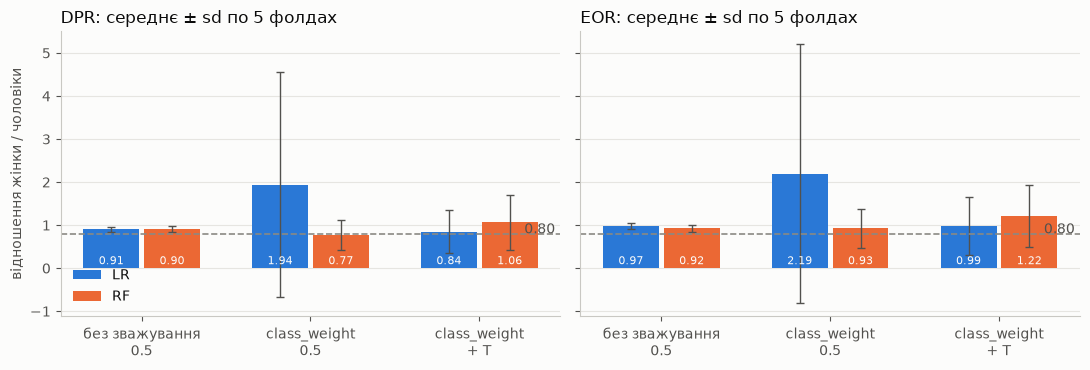

In [5]:
labels = ["без зважування, поріг 0.5", "class_weight, поріг 0.5", "class_weight + оптимальний T"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric in zip(axes, ("DPR", "EOR")):
    x = np.arange(len(labels)); w = 0.36
    for k, (m, color) in enumerate((("LR", BLUE), ("RF", ORANGE))):
        sub = fair.set_index(["модель", "конфігурація"]).loc[m].loc[labels]
        ax.bar(x + (k - 0.5) * w, sub[f"_{metric}"], w * 0.92, color=color, label=m,
               yerr=sub[f"_{metric}_sd"], capsize=3, error_kw={"ecolor": "#52514e", "lw": 1})
        for xi, val in zip(x, sub[f"_{metric}"]):
            ax.text(xi + (k - 0.5) * w, 0.03, f"{val:.2f}", ha="center", va="bottom", fontsize=8, color="#fcfcfb")
    ax.axhline(0.8, color=GRAY, ls="--", lw=1.2); ax.text(2.45, 0.81, "0.80", color="#52514e", ha="right")
    ax.set_xticks(x, ["без зважування\n0.5", "class_weight\n0.5", "class_weight\n+ T"])
    ax.set_title(f"{metric}: середнє ± sd по 5 фолдах", loc="left"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("відношення жінки / чоловіки"); axes[0].legend(frameon=False, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "fairness_trusted.png", dpi=130); plt.show()

## 4. Вплив SMOTE на захищену ознаку (п. 4.3, CACE)


In [6]:
smote_rows = []
for m in ("LR", "RF"):
    for r in RES[(m, "base")]:
        a = r["resampling_audit"]
        smote_rows.append({"модель": m, "фолд": r["fold"], "bad до": a["n_minority_before"], "синтетичних": a["n_synthetic"],
                           "жінки серед bad до": a["minority_before"].get("female", 0),
                           "жінки серед bad після": a["minority_after"].get("female", 0),
                           "змішаних пар": a["mixed_pairs_share"]})
smote = pd.DataFrame(smote_rows); smote.to_csv(ART / "smote_group_audit.csv", index=False)
display(smote.round(3))
smote.groupby("модель")[["жінки серед bad до", "жінки серед bad після", "змішаних пар"]].agg(["mean", "std"]).round(3)

,модель,фолд,bad до,синтетичних,жінки серед bad до,жінки серед bad після,змішаних пар
0,LR,0,240,320,0.371,0.350,0.419
1,LR,1,240,320,0.350,0.332,0.409
2,LR,2,240,320,0.358,0.361,0.428
3,LR,3,240,320,0.371,0.357,0.359
4,LR,4,240,320,0.367,0.364,0.412
5,RF,0,240,320,0.371,0.350,0.512
6,RF,1,240,320,0.350,0.389,0.478
7,RF,2,240,320,0.358,0.370,0.469
8,RF,3,240,320,0.371,0.396,0.453
9,RF,4,240,320,0.367,0.377,0.372


жінки серед bad до        жінки серед bad після        змішаних пар       
                     mean    std                  mean    std         mean    std
модель                                                                           
LR                  0.363  0.009                 0.353  0.013        0.406  0.027
RF                  0.363  0.009                 0.376  0.018        0.457  0.052

## 5. Об'єднана оцінка по 1000 OOF-рядках з бутстреп-інтервалом



In [7]:
def pooled_decisions(res, thr):
    granted = np.zeros(len(X), dtype=bool)
    for r in res:
        t = 0.5 if thr == "0.5" else r["threshold"]
        granted[r["test_idx"]] = r["p_test"] < t
    return granted

def ratios(granted, yv, g):
    priv = g == FAIR["privileged"]; good = yv == 0
    return granted[~priv].mean() / granted[priv].mean(), granted[~priv & good].mean() / granted[priv & good].mean()

def pooled_row(m, v, thr, label, n_boot=2000, seed=0):
    granted = pooled_decisions(RES[(m, v)], thr)
    dpr, eor = ratios(granted, y, group)
    rng = np.random.default_rng(seed); boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        try: boots.append(ratios(granted[i], y[i], group[i]))
        except ZeroDivisionError: pass
    b = np.array(boots)
    return {"модель": m, "конфігурація": label, "схвалено, %": round(100 * granted.mean(), 1),
            "схвалено жінок / чоловіків": f"{int(granted[group != FAIR['privileged']].sum())} / {int(granted[group == FAIR['privileged']].sum())}",
            "DPR (pooled)": round(dpr, 3), "DPR 95% CI": f"{np.nanpercentile(b[:, 0], 2.5):.2f}–{np.nanpercentile(b[:, 0], 97.5):.2f}",
            "EOR (pooled)": round(eor, 3), "EOR 95% CI": f"{np.nanpercentile(b[:, 1], 2.5):.2f}–{np.nanpercentile(b[:, 1], 97.5):.2f}"}

pooled = pd.DataFrame([pooled_row(m, v, thr, label) for m in ("LR", "RF")
                       for v, thr, label in (("base", "0.5", "без зважування, 0.5"), ("cs", "0.5", "class_weight, 0.5"),
                                             ("cs", "inner", "class_weight + T"), ("base", "inner", "без зважування + T"),
                                             ("nosmote", "0.5", "без SMOTE, 0.5"))])
pooled.to_csv(ART / "fairness_pooled.csv", index=False)
pooled

,модель,конфігурація,"схвалено, %",схвалено жінок / чоловіків,DPR (pooled),DPR 95% CI,EOR (pooled),EOR 95% CI
0,LR,"без зважування, 0.5",57.3,166 / 407,0.908,0.80–1.02,0.979,0.87–1.09
1,LR,"class_weight, 0.5",6.3,18 / 45,0.890,0.49–1.45,0.981,0.54–1.62
2,LR,class_weight + T,9.0,23 / 67,0.764,0.46–1.16,0.841,0.50–1.30
3,LR,без зважування + T,14.5,46 / 99,1.034,0.74–1.40,1.076,0.75–1.50
4,LR,"без SMOTE, 0.5",80.2,244 / 558,0.973,0.91–1.04,0.984,0.92–1.04
5,RF,"без зважування, 0.5",61.8,178 / 440,0.900,0.80–1.00,0.926,0.82–1.03
6,RF,"class_weight, 0.5",6.5,17 / 48,0.788,0.43–1.28,0.938,0.51–1.52
7,RF,class_weight + T,8.1,25 / 56,0.994,0.61–1.53,1.124,0.68–1.72
8,RF,без зважування + T,12.6,36 / 90,0.890,0.60–1.24,0.927,0.63–1.33
9,RF,"без SMOTE, 0.5",88.3,279 / 604,1.028,0.98–1.07,1.012,0.97–1.05


In [8]:
json.dump({"lab2": lab2_rows, "trusted": fair[[c for c in fair.columns if not c.startswith("_")]].to_dict("records"),
           "smote": smote.groupby("модель")[["жінки серед bad до", "жінки серед bad після", "змішаних пар"]].mean().round(4).to_dict()},
          open(ART / "summary_fairness.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False, default=float)
print("збережено")

збережено